# Bài 2 (Trang 28) – Bank marketing
Tải `bank.csv` (thư mục Dataset/bank trên Drive) lên Files của Colab trước khi chạy.

In [1]:
# ===== Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản, xác định loại thuộc tính =====
print("Nguyễn Bình Minh - 6451071047")

import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# File bank.csv phân tách bằng dấu chấm phẩy
df = pd.read_csv('bank.csv', sep=';')
df_goc = df.copy()   # bản gốc, dùng để vẽ biểu đồ ở Câu 3, 4, 5
print('Kích thước:', df.shape)
display(df.head(12))
df.info()
display(df.describe())
display(df.describe(include='object'))

print('Loại thuộc tính:')
print('- job, marital, contact, poutcome : Nominal')
print('- education, month                : Ordinal')
print('- default, housing, loan          : Binary - Asymmetric')
print('- y                               : Binary - thuộc tính quyết định')
print('- age, balance, duration, campaign, pdays, previous : Numeric - Ratio-scaled')
print('- day                             : Numeric - Interval-scaled')

Nguyễn Bình Minh - 6451071047


Kích thước: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,unknown,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,unknown,14,may,57,2,-1,0,unknown,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no


<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


Loại thuộc tính:
- job, marital, contact, poutcome : Nominal
- education, month                : Ordinal
- default, housing, loan          : Binary - Asymmetric
- y                               : Binary - thuộc tính quyết định
- age, balance, duration, campaign, pdays, previous : Numeric - Ratio-scaled
- day                             : Numeric - Interval-scaled


In [2]:
# ===== Câu 2: 5 thuộc tính có số lượng giá trị thiếu nhiều nhất =====
print("Nguyễn Bình Minh - 6451071047")

# Dữ liệu không có ô rỗng (NaN) mà ghi giá trị thiếu bằng chữ 'unknown'
print('Số ô NaN:', df.isnull().sum().sum())
tmp = df.replace('unknown', np.nan)
total = tmp.isnull().sum().sort_values(ascending=False)
percent_1 = tmp.isnull().sum() / tmp.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
display(missing_data.head(5))

print('Nhận xét:')
print("- Không có ô rỗng, giá trị thiếu được ghi là 'unknown'.")
print('- poutcome thiếu 81.9%, contact 29.3%, education 4.1%, job 0.8%; các thuộc tính khác đầy đủ.')
print('- poutcome thiếu rất nghiêm trọng, sẽ ảnh hưởng lớn nếu dùng trong khai thác.')

Nguyễn Bình Minh - 6451071047
Số ô NaN: 0


,Total,%
poutcome,3705,82.0
contact,1324,29.3
education,187,4.1
job,38,0.8
age,0,0.0


Nhận xét:
- Không có ô rỗng, giá trị thiếu được ghi là 'unknown'.
- poutcome thiếu 81.9%, contact 29.3%, education 4.1%, job 0.8%; các thuộc tính khác đầy đủ.
- poutcome thiếu rất nghiêm trọng, sẽ ảnh hưởng lớn nếu dùng trong khai thác.


Nguyễn Bình Minh - 6451071047


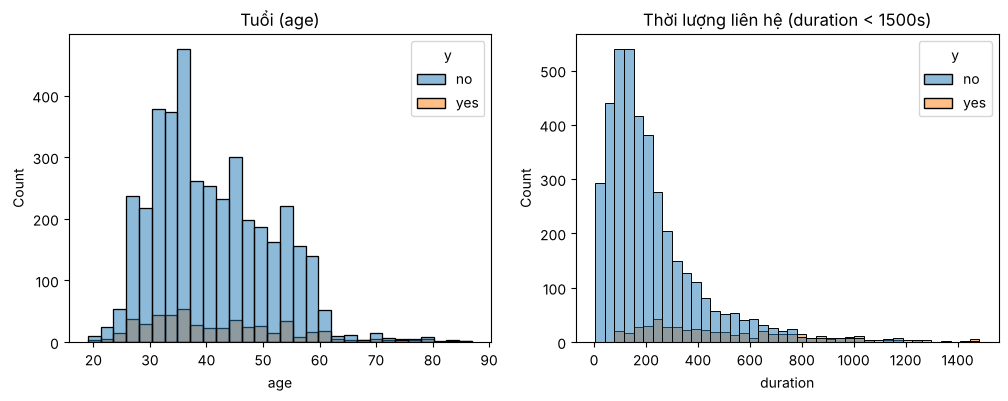

age
(0, 25]      0.207
(25, 30]     0.129
(30, 40]     0.099
(40, 50]     0.106
(50, 60]     0.102
(60, 100]    0.378
Name: sub, dtype: float64 

duration
(0, 100]        0.014
(100, 200]      0.040
(200, 300]      0.116
(300, 500]      0.188
(500, 1000]     0.347
(1000, 5000]    0.570
Name: sub, dtype: float64
Nhận xét:
- Chỉ 11.5% khách hàng đăng ký (dữ liệu mất cân bằng).
- Theo tuổi: dưới 25 tuổi (~21%) và trên 60 tuổi (~38%) đăng ký cao nhất; 30-60 tuổi chỉ ~10%.
- Theo duration: liên hệ càng lâu thì tỉ lệ đăng ký càng cao, từ ~1% (<100s) lên ~57% (>1000s).
- duration là thuộc tính liên quan mạnh nhất đến y.


In [3]:
# ===== Câu 3: Liên quan giữa age, duration và khả năng đăng ký (y) =====
print("Nguyễn Bình Minh - 6451071047")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.histplot(data=df_goc, x='age', hue='y', bins=30, ax=axes[0])
axes[0].set_title('Tuổi (age)')
sns.histplot(data=df_goc[df_goc['duration'] < 1500], x='duration', hue='y', bins=40, ax=axes[1])
axes[1].set_title('Thời lượng liên hệ (duration < 1500s)')
plt.show()

d = df_goc.copy()
d['sub'] = (d['y'] == 'yes').astype(int)
print(d.groupby(pd.cut(d['age'], [0, 25, 30, 40, 50, 60, 100]))['sub'].mean().round(3), '\n')
print(d.groupby(pd.cut(d['duration'], [0, 100, 200, 300, 500, 1000, 5000]))['sub'].mean().round(3))

print('Nhận xét:')
print('- Chỉ 11.5% khách hàng đăng ký (dữ liệu mất cân bằng).')
print('- Theo tuổi: dưới 25 tuổi (~21%) và trên 60 tuổi (~38%) đăng ký cao nhất; 30-60 tuổi chỉ ~10%.')
print('- Theo duration: liên hệ càng lâu thì tỉ lệ đăng ký càng cao, từ ~1% (<100s) lên ~57% (>1000s).')
print('- duration là thuộc tính liên quan mạnh nhất đến y.')

Nguyễn Bình Minh - 6451071047


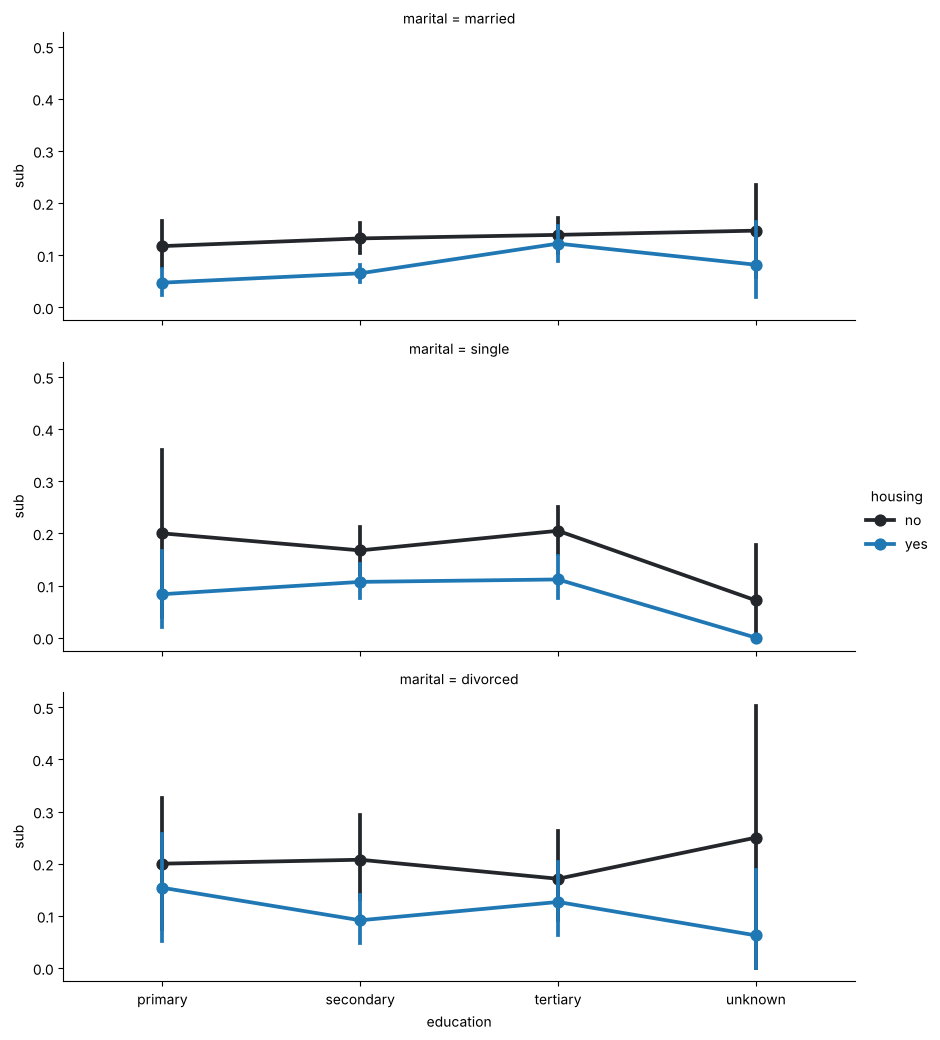

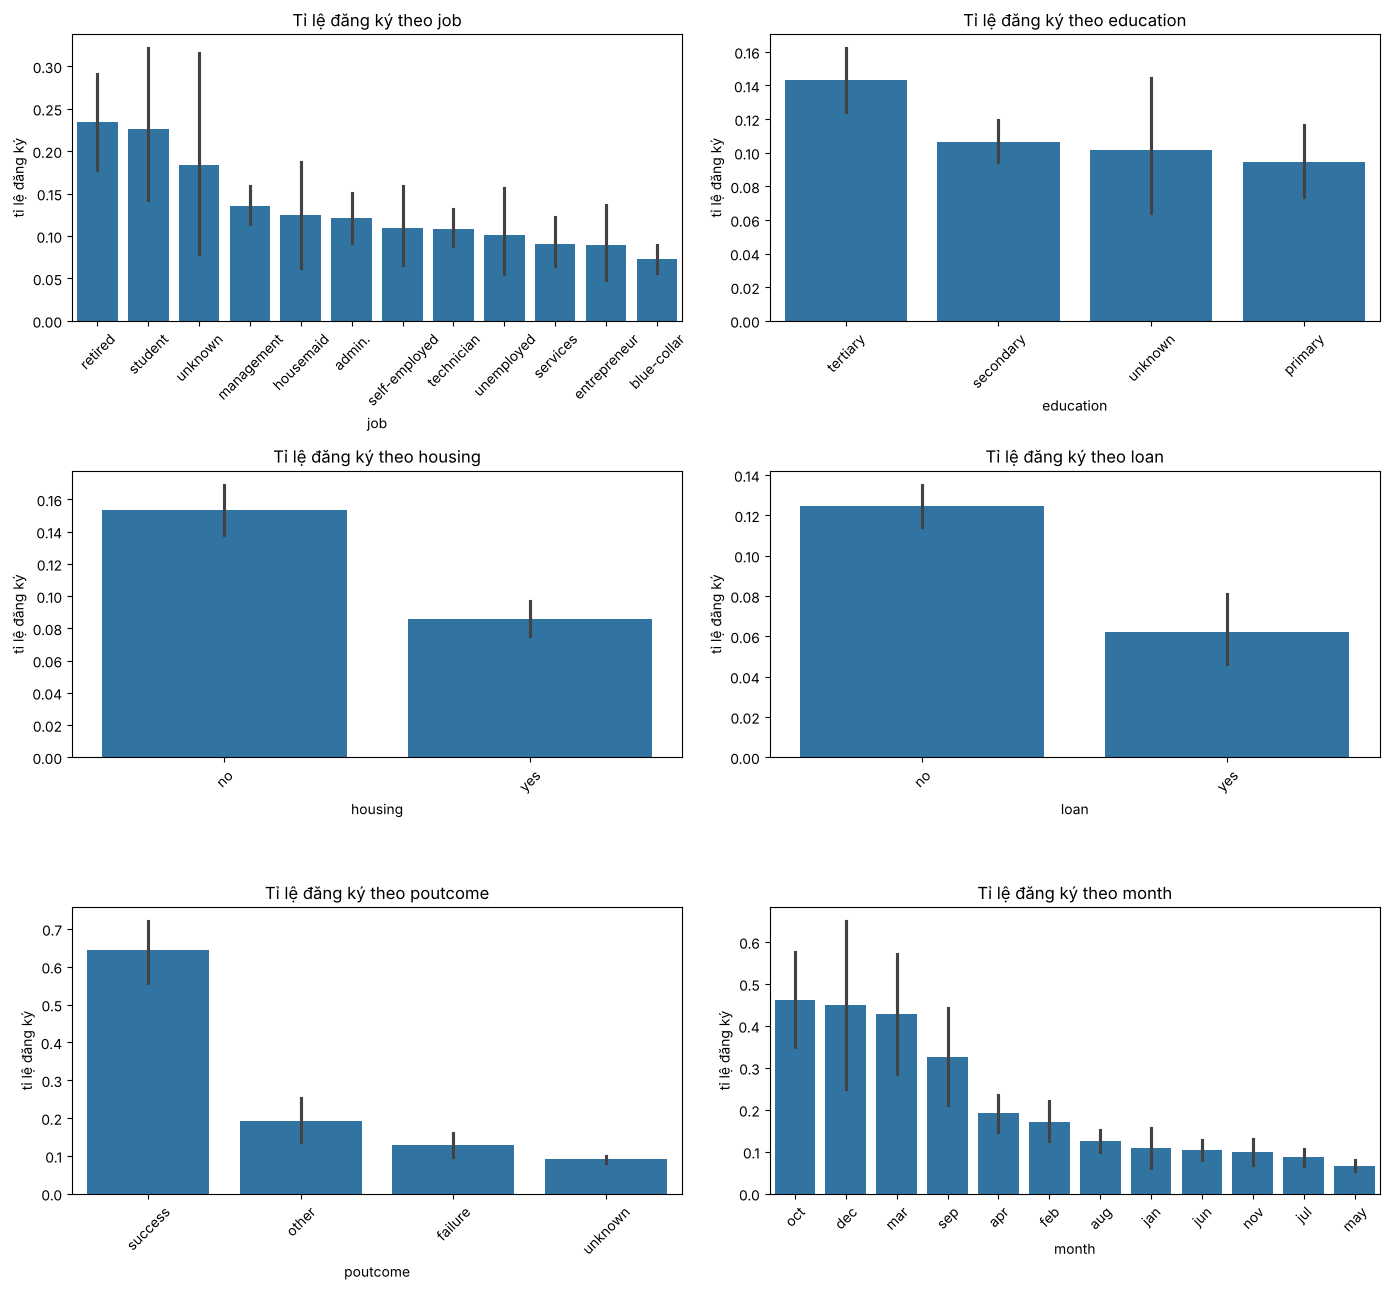

Nhận xét:
- Ở hầu hết các nhóm marital và education, người không vay mua nhà (housing=no) đăng ký nhiều hơn người có vay.
- job: retired (~24%) và student (~23%) đăng ký nhiều nhất; blue-collar thấp nhất (~7%).
- marital: divorced (~15%) và single (~14%) đăng ký nhiều hơn married (~10%).
- education: tertiary (~14%) cao hơn secondary (~11%) và primary (~9%).
- Người không có khoản vay mua nhà (housing=no, ~15%) hoặc vay cá nhân (loan=no, ~13%) đăng ký nhiều hơn.
- poutcome = success thì tỉ lệ đăng ký rất cao (~64%).
- Tháng oct, dec, mar có tỉ lệ đăng ký cao (>40%), tháng may thấp nhất (~7%).


In [4]:
# ===== Câu 4: Liên quan giữa job, marital, education, housing, loan, poutcome với y, phân biệt theo marital =====
print("Nguyễn Bình Minh - 6451071047")

d = df_goc.copy()
d['sub'] = (d['y'] == 'yes').astype(int)

FacetGrid = sns.FacetGrid(d, row='marital', height=3.5, aspect=2.5)
FacetGrid.map(sns.pointplot, 'education', 'sub', 'housing', palette=None,
              order=['primary', 'secondary', 'tertiary', 'unknown'], hue_order=['no', 'yes'])
FacetGrid.add_legend(title='housing')
plt.show()

cols = ['job', 'education', 'housing', 'loan', 'poutcome', 'month']
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 13))
for ax, col in zip(axes.flat, cols):
    order = d.groupby(col)['sub'].mean().sort_values(ascending=False).index
    sns.barplot(x=col, y='sub', data=d, ax=ax, order=order)
    ax.set_title(f'Tỉ lệ đăng ký theo {col}')
    ax.set_ylabel('tỉ lệ đăng ký')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('Nhận xét:')
print('- Ở hầu hết các nhóm marital và education, người không vay mua nhà (housing=no) đăng ký nhiều hơn người có vay.')
print('- job: retired (~24%) và student (~23%) đăng ký nhiều nhất; blue-collar thấp nhất (~7%).')
print('- marital: divorced (~15%) và single (~14%) đăng ký nhiều hơn married (~10%).')
print('- education: tertiary (~14%) cao hơn secondary (~11%) và primary (~9%).')
print('- Người không có khoản vay mua nhà (housing=no, ~15%) hoặc vay cá nhân (loan=no, ~13%) đăng ký nhiều hơn.')
print('- poutcome = success thì tỉ lệ đăng ký rất cao (~64%).')
print('- Tháng oct, dec, mar có tỉ lệ đăng ký cao (>40%), tháng may thấp nhất (~7%).')

Nguyễn Bình Minh - 6451071047
contacted_before
0    3705
1     816
Name: count, dtype: int64 



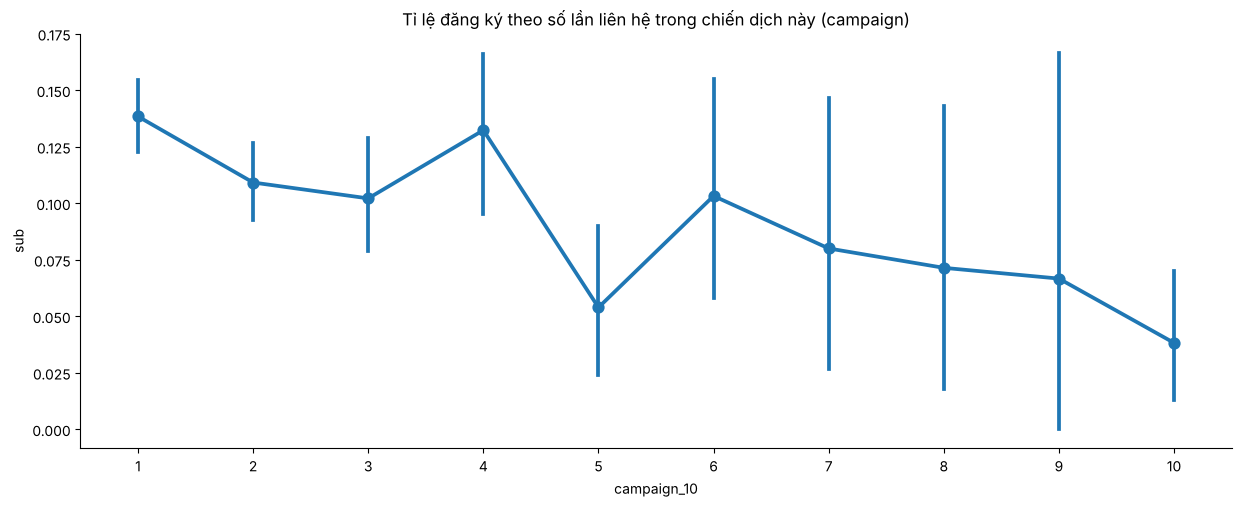

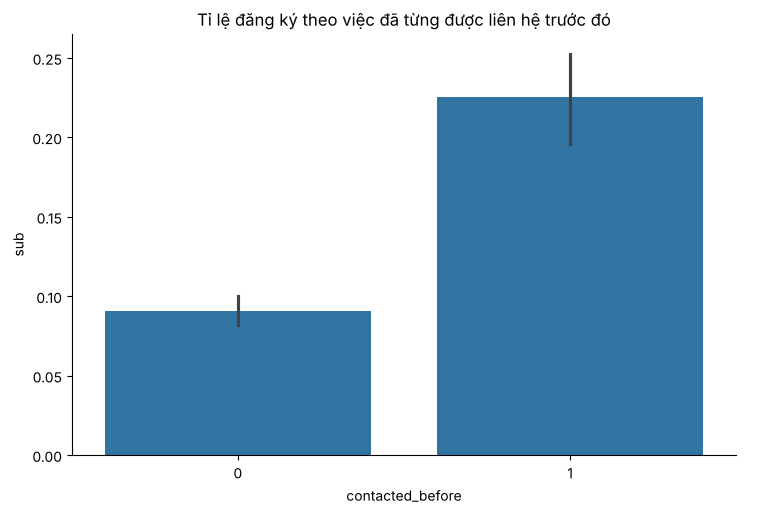

Nhận xét:
- 3705 khách chưa từng được liên hệ ở chiến dịch trước (contacted_before = 0), 816 khách đã từng.
- Liên hệ 1 lần có tỉ lệ đăng ký cao nhất (~14%); liên hệ càng nhiều lần (>= 5) thì tỉ lệ càng giảm (~4-8%).
- Khách đã từng được liên hệ trước đó đăng ký nhiều hơn hẳn (~23% so với ~9%).


In [5]:
# ===== Câu 5: Thống kê số lần liên hệ (campaign, previous) và liên quan với y =====
print("Nguyễn Bình Minh - 6451071047")

for dataset in [df]:
    dataset['contacted_before'] = 0
    dataset.loc[dataset['pdays'] != -1, 'contacted_before'] = 1
print(df['contacted_before'].value_counts(), '\n')

d = df.copy()
d['sub'] = (d['y'] == 'yes').astype(int)
d['campaign_10'] = d['campaign'].clip(upper=10)   # gộp >= 10 lần vào nhóm 10
sns.catplot(x='campaign_10', y='sub', data=d, aspect=2.5, kind='point')
plt.title('Tỉ lệ đăng ký theo số lần liên hệ trong chiến dịch này (campaign)')
plt.show()
sns.catplot(x='contacted_before', y='sub', data=d, aspect=1.5, kind='bar')
plt.title('Tỉ lệ đăng ký theo việc đã từng được liên hệ trước đó')
plt.show()

print('Nhận xét:')
print('- 3705 khách chưa từng được liên hệ ở chiến dịch trước (contacted_before = 0), 816 khách đã từng.')
print('- Liên hệ 1 lần có tỉ lệ đăng ký cao nhất (~14%); liên hệ càng nhiều lần (>= 5) thì tỉ lệ càng giảm (~4-8%).')
print('- Khách đã từng được liên hệ trước đó đăng ký nhiều hơn hẳn (~23% so với ~9%).')

In [6]:
# ===== Câu 6: Tiền xử lý thuộc tính thiếu dữ liệu và xóa thuộc tính không cần thiết =====
print("Nguyễn Bình Minh - 6451071047")

# Đổi 'unknown' thành NaN để xử lý
df = df.replace('unknown', np.nan)
print(df.isnull().sum()[lambda s: s > 0], '\n')

# job, education (categorical, thiếu ít): điền bằng mode
for col in ['job', 'education']:
    common_value = df[col].mode()[0]
    print(f'Mode của {col}: {common_value}')
    df[col] = df[col].fillna(common_value)

# contact (thiếu 29.3%): xem giá trị thiếu là một loại mới
df['contact'] = df['contact'].fillna('other')

# poutcome thiếu 81.9% -> xóa; day (ngày trong tháng) ít ý nghĩa -> xóa
df = df.drop(['poutcome'], axis=1)
df = df.drop(['day'], axis=1)

df.info()
print(df.isnull().sum())

Nguyễn Bình Minh - 6451071047
job            38
education     187
contact      1324
poutcome     3705
dtype: int64 

Mode của job: management
Mode của education: secondary
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               4521 non-null   int64
 1   job               4521 non-null   str  
 2   marital           4521 non-null   str  
 3   education         4521 non-null   str  
 4   default           4521 non-null   str  
 5   balance           4521 non-null   int64
 6   housing           4521 non-null   str  
 7   loan              4521 non-null   str  
 8   contact           4521 non-null   str  
 9   month             4521 non-null   str  
 10  duration          4521 non-null   int64
 11  campaign          4521 non-null   int64
 12  pdays             4521 non-null   int64
 13  previous          4521 non-null   int64
 14  y      

In [7]:
# ===== Câu 7: Biến đổi các thuộc tính =====
print("Nguyễn Bình Minh - 6451071047")

# a) Binary yes/no -> 0/1
yes_no = {"no": 0, "yes": 1}
for col in ['default', 'housing', 'loan', 'y']:
    df[col] = df[col].map(yes_no)

# b) marital, contact -> số
df['marital'] = df['marital'].map({"single": 0, "married": 1, "divorced": 2})
df['contact'] = df['contact'].map({"cellular": 0, "telephone": 1, "other": 2})

# c) education, month có thứ tự -> mã hóa theo thứ tự
df['education'] = df['education'].map({"primary": 0, "secondary": 1, "tertiary": 2})
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
df['month'] = df['month'].map({m: i + 1 for i, m in enumerate(months)})

# d) job nhiều giá trị, không thứ tự -> One-hot Encoding
df = pd.get_dummies(df, columns=['job'], prefix='job', dtype=int)

# e) Chia age thành 6 nhóm
for dataset in [df]:
    dataset.loc[ dataset['age'] <= 25, 'age'] = 0
    dataset.loc[(dataset['age'] > 25) & (dataset['age'] <= 30), 'age'] = 1
    dataset.loc[(dataset['age'] > 30) & (dataset['age'] <= 40), 'age'] = 2
    dataset.loc[(dataset['age'] > 40) & (dataset['age'] <= 50), 'age'] = 3
    dataset.loc[(dataset['age'] > 50) & (dataset['age'] <= 60), 'age'] = 4
    dataset.loc[ dataset['age'] > 60, 'age'] = 5
print(df['age'].value_counts().sort_index(), '\n')

# f) Chia balance thành 5 nhóm có số lượng cân bằng (qcut)
df['balance'] = pd.qcut(df['balance'], q=5, labels=[0, 1, 2, 3, 4]).astype(int)
print(df['balance'].value_counts().sort_index(), '\n')

# g) Chuẩn hóa duration bằng Min-max normalization
dmin, dmax = df['duration'].min(), df['duration'].max()
df['duration'] = ((df['duration'] - dmin) / (dmax - dmin)).round(4)
print(df['duration'].describe())

display(df.head(10))

Nguyễn Bình Minh - 6451071047
age
0     111
1     521
2    1800
3    1162
4     800
5     127
Name: count, dtype: int64 

balance
0    913
1    899
2    903
3    902
4    904
Name: count, dtype: int64 

count    4521.000000
mean        0.086052
std         0.086017
min         0.000000
25%         0.033100
50%         0.059900
75%         0.107600
max         1.000000
Name: duration, dtype: float64


,age,marital,education,default,balance,housing,loan,contact,month,duration,...,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed
0,1,1,0,0,3,0,0,0,10,0.0248,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,0,4,1,1,0,5,0.0715,...,0,0,0,0,0,0,1,0,0,0
2,2,0,2,0,3,1,0,0,4,0.0599,...,0,0,0,1,0,0,0,0,0,0
3,1,1,2,0,3,1,1,2,6,0.0645,...,0,0,0,1,0,0,0,0,0,0
4,4,1,1,0,0,1,0,2,5,0.0735,...,1,0,0,0,0,0,0,0,0,0
5,2,0,2,0,3,0,0,0,2,0.0453,...,0,0,0,1,0,0,0,0,0,0
6,2,1,2,0,2,1,0,0,5,0.1116,...,0,0,0,0,0,1,0,0,0,0
7,2,1,1,0,1,1,0,0,5,0.0487,...,0,0,0,0,0,0,0,0,1,0
8,3,1,2,0,1,1,0,2,5,0.0175,...,0,1,0,0,0,0,0,0,0,0
9,3,1,0,0,0,1,1,0,4,0.1023,...,0,0,0,0,0,0,1,0,0,0


In [8]:
# ===== Câu 8: Tạo các thuộc tính mới =====
print("Nguyễn Bình Minh - 6451071047")

# Tổng số lần liên hệ (chiến dịch này + các chiến dịch trước)
for dataset in [df]:
    dataset['total_contacts'] = dataset['campaign'] + dataset['previous']

# Tuổi * học vấn (tương tự age_class của Titanic)
for dataset in [df]:
    dataset['age_education'] = dataset['age'] * dataset['education']

display(df[['age', 'education', 'age_education', 'campaign', 'previous',
            'total_contacts', 'contacted_before', 'y']].head(10))
df.info()

Nguyễn Bình Minh - 6451071047


,age,education,age_education,campaign,previous,total_contacts,contacted_before,y
0,1,0,0,1,0,1,0,0
1,2,1,2,1,4,5,1,0
2,2,2,4,1,1,2,1,0
3,1,2,2,4,0,4,0,0
4,4,1,4,1,0,1,0,0
5,2,2,4,2,3,5,1,0
6,2,2,4,1,2,3,1,0
7,2,1,2,2,0,2,0,0
8,3,2,6,2,0,2,0,0
9,3,0,0,1,2,3,1,0


<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                4521 non-null   int64  
 1   marital            4521 non-null   int64  
 2   education          4521 non-null   int64  
 3   default            4521 non-null   int64  
 4   balance            4521 non-null   int64  
 5   housing            4521 non-null   int64  
 6   loan               4521 non-null   int64  
 7   contact            4521 non-null   int64  
 8   month              4521 non-null   int64  
 9   duration           4521 non-null   float64
 10  campaign           4521 non-null   int64  
 11  pdays              4521 non-null   int64  
 12  previous           4521 non-null   int64  
 13  y                  4521 non-null   int64  
 14  contacted_before   4521 non-null   int64  
 15  job_admin.         4521 non-null   int64  
 16  job_blue-collar    4521 non-null   